# Prática 3 — Futebol Analytics com YOLO (Colab)
**Antes de rodar:** `Ambiente de execução → Alterar tipo de ambiente → GPU T4`.

No seu Google Drive, crie a pasta `P3_VC/dados/` e coloque nela o trecho baixado com o nome **`jogo_clip.mp4`**.
Todas as saídas (`saidas/`, `figuras/`) são gravadas em `MyDrive/P3_VC/`, para não se perderem quando o Colab desconectar.

## 0 · Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

BASE  = '/content/drive/MyDrive/P3_VC'
VIDEO = f'{BASE}/dados/jogo_clip.mp4'
SAIDA = f'{BASE}/saidas'

import os; os.makedirs(SAIDA, exist_ok=True)
assert os.path.exists(VIDEO), f'Coloque o vídeo em {VIDEO}'
!nvidia-smi --query-gpu=name,memory.total --format=csv

Mounted at /content/drive
name, memory.total [MiB]
Tesla T4, 15360 MiB


In [2]:
%cd /content
!git clone -q https://github.com/eron93br/vc-20262-p3.git src 2>/dev/null || (cd src && git pull -q)
%cd /content/src
!pip install -q ultralytics
# copia o vídeo para o disco local do Colab (leitura muito mais rápida que pelo Drive)
!cp "{VIDEO}" /content/jogo_clip.mp4
VLOCAL = '/content/jogo_clip.mp4'

/content
/content/src


## 1 · Informações do vídeo (Q1.2)

In [ ]:
import cv2
cap = cv2.VideoCapture(VLOCAL)
fps = cap.get(cv2.CAP_PROP_FPS); n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
W, H = int(cap.get(3)), int(cap.get(4)); cap.release()
print(f'Resolução: {W}x{H} | fps: {fps:.2f} | quadros: {n} | duração: {n/fps/60:.2f} min')

Resolução: 1280x720 | fps: 59.94 | quadros: 14386 | duração: 4.00 min


In [ ]:
import cv2
cap = cv2.VideoCapture(VLOCAL); fps = cap.get(cv2.CAP_PROP_FPS)
ant, cortes, f = None, [], 0
while True:
    ok, fr = cap.read()
    if not ok: break
    hsv = cv2.cvtColor(cv2.resize(fr, (320, 180)), cv2.COLOR_BGR2HSV)
    h = cv2.calcHist([hsv], [0, 1], None, [30, 32], [0, 180, 0, 256]); cv2.normalize(h, h)
    if ant is not None and cv2.compareHist(ant, h, cv2.HISTCMP_CORREL) < 0.5:
        cortes.append(f / fps)
    ant, f = h, f + 1
cap.release()
print('Cortes em (tempo do clipe):', [f'{int(t//60)}:{t%60:04.1f}' for t in cortes])

Cortes em (tempo do clipe): ['1:02.4', '1:04.7', '1:49.6', '2:04.5', '2:19.0', '2:22.4', '2:26.5', '2:31.4', '3:03.0', '3:04.6', '3:28.4', '3:32.5', '3:50.4']


## 2 · Detecção — comparação de modelos em 30 s (Q2.1)
Mesmo subtrecho de 30 s (`--inicio 0 --fim 0.5`, em minutos **do clipe**) com dois tamanhos de YOLO.
Escolham um subtrecho com jogo corrido; se o começo do clipe for ruim, mudem `INI`.

In [ ]:
INI, FIM = 0.0, 0.5   # minutos dentro do clipe (30 s)
MODELOS = ['yolov8n.pt', 'yolov8m.pt']   # pode trocar/adicionar: 'yolov8s.pt', 'yolo11m.pt'

for m in MODELOS:
    nome = m.replace('.pt', '')
    !python detectar_rastrear.py --video {VLOCAL} --saida {SAIDA}/teste30s_{nome} --modelo {m} --inicio {INI} --fim {FIM} --imgsz 1280

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Device: cuda | Modelo: yolov8n.pt | 1280x720 @ 59.94 fps
Classes pessoa: ['person'] | bola: ['sports ball']
Rastreando:   0% 0/1798 [00:00<?, ?quadro/s]requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 217ms
Prepared 1 package in 384ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 0.8s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

Rastreando: 1799quadro [01:32, 19.37quadro/s]          

1799 quadros em 92.9s (19.4 fps). Saída: /content/drive/MyDrive/P3_VC/saidas/teste30s_yolov8n/
Device: cuda | Modelo: yolov8m.pt | 1280x720 @

In [ ]:
import pandas as pd, json
def resumo(pasta, rotulo):
    meta = json.load(open(f'{pasta}/meta.json'))
    tr = pd.read_csv(f'{pasta}/tracks.csv')
    nf = meta['n_frames']
    pessoas = tr[tr.classe != 'bola'].groupby('frame').size()
    bola_frames = tr[tr.classe == 'bola'].frame.nunique()
    return {'config': rotulo, 'imgsz': meta['imgsz'], 'fps_proc': round(meta['fps_processamento'], 1),
            'jogadores/quadro': round(pessoas.reindex(range(nf), fill_value=0).mean(), 1),
            '% quadros c/ bola': round(100 * bola_frames / nf, 1), 'quadros': nf}

tab = pd.DataFrame([resumo(f'{SAIDA}/teste30s_{m.replace(".pt","")}', m) for m in MODELOS])
tab.to_csv(f'{SAIDA}/comparacao_modelos.csv', index=False)
tab

,config,imgsz,fps_proc,jogadores/quadro,% quadros c/ bola,quadros
0,yolov8n.pt,1280,19.4,10.7,70.5,1799
1,yolov8m.pt,1280,6.2,11.1,75.2,1799


In [ ]:
for m in MODELOS:
    tr = pd.read_csv(f'{SAIDA}/teste30s_{m.replace(".pt","")}/tracks.csv')
    b = tr[tr.classe == 'bola']; nf = 1799
    print(f"{m}: bola conf≥0.3 em {100*b[b.conf>=0.3].frame.nunique()/nf:.1f}% dos quadros | "
          f"quadros com >1 candidata: {100*(b.groupby('frame').size()>1).sum()/nf:.1f}% | "
          f"conf mediana da bola: {b.conf.median():.2f}")

yolov8n.pt: bola conf≥0.3 em 39.5% dos quadros | quadros com >1 candidata: 10.1% | conf mediana da bola: 0.29
yolov8m.pt: bola conf≥0.3 em 50.8% dos quadros | quadros com >1 candidata: 20.9% | conf mediana da bola: 0.33


In [ ]:
extra = []
for m in MODELOS:
    tr = pd.read_csv(f'{SAIDA}/teste30s_{m.replace(".pt","")}/tracks.csv')
    b = tr[tr.classe == 'bola']; nf = 1799
    extra.append({'% bola conf>=0.3': round(100*b[b.conf>=0.3].frame.nunique()/nf, 1),
                  '% quadros >1 candidata': round(100*(b.groupby('frame').size()>1).sum()/nf, 1),
                  'conf mediana bola': round(b.conf.median(), 2)})
tab = pd.concat([tab, pd.DataFrame(extra)], axis=1)
tab.to_csv(f'{SAIDA}/comparacao_modelos.csv', index=False); tab

,config,imgsz,fps_proc,jogadores/quadro,% quadros c/ bola,quadros,% bola conf>=0.3,% quadros >1 candidata,conf mediana bola
0,yolov8n.pt,1280,19.4,10.7,70.5,1799,39.5,10.1,0.29
1,yolov8m.pt,1280,6.2,11.1,75.2,1799,50.8,20.9,0.33


### Q2.3 · Efeito de `--imgsz` e `--conf-bola` (opcional mas vale nota)
Mesmo modelo, variando a resolução de inferência e o limiar da bola.

In [ ]:
M = 'yolov8m.pt'
for imgsz, cb in [(640, 0.10), (1280, 0.05), (1280, 0.25)]:
    !python detectar_rastrear.py --video {VLOCAL} --saida {SAIDA}/teste30s_m_{imgsz}_cb{cb} --modelo {M} --inicio {INI} --fim {FIM} --imgsz {imgsz} --conf-bola {cb} --sem-video

linhas = [resumo(f'{SAIDA}/teste30s_yolov8m', 'm 1280 cb0.10')]
linhas += [resumo(f'{SAIDA}/teste30s_m_{i}_cb{c}', f'm {i} cb{c}') for i, c in [(640,0.10),(1280,0.05),(1280,0.25)]]
tab2 = pd.DataFrame(linhas); tab2.to_csv(f'{SAIDA}/comparacao_imgsz_confbola.csv', index=False); tab2

## 3 · Rastreamento + times no trecho completo
Rodem com o modelo escolhido no passo 2. Em T4, ~4 min de vídeo levam algo como 10–25 min.
Depois **baixem e assistam** `saidas/jogo1/rastreado.mp4` (Q3.1: trocas de ID; Q3.2: cores dos times).

In [ ]:
MODELO = 'yolov8m.pt'
!python detectar_rastrear.py --video {VLOCAL} --saida {SAIDA}/jogo1 --modelo {MODELO} --imgsz 1280

In [ ]:
meta = json.load(open(f'{SAIDA}/jogo1/meta.json'))
print(json.dumps({k: meta[k] for k in ['n_frames','fps','fps_processamento','times_bgr']}, indent=2))

# mostra as cores dos centróides dos times (Q3.2)
import numpy as np, matplotlib.pyplot as plt
cores = meta['times_bgr']
fig, ax = plt.subplots(1, len(cores), figsize=(2*len(cores), 2))
for a, (t, bgr) in zip(np.atleast_1d(ax), cores.items()):
    a.imshow(np.full((10,10,3), bgr[::-1], dtype=np.uint8)); a.set_title(f'time {t}'); a.axis('off')
plt.show()

### Q3.3 · Teste com `--k 3` (separar árbitro/goleiros)
Só no subtrecho de 30 s, para comparar com `k=2`.

In [ ]:
!python detectar_rastrear.py --video {VLOCAL} --saida {SAIDA}/teste30s_k3 --modelo {MODELO} --inicio {INI} --fim {FIM} --k 3
print(json.load(open(f'{SAIDA}/teste30s_k3/meta.json'))['times_bgr'])

In [3]:
import os
D30 = f'{BASE}/dados/jogo_clip30.mp4'
VLOCAL30 = '/content/jogo_clip30.mp4'
if not os.path.exists(D30):
    !ffmpeg -y -stats -loglevel error -i {VLOCAL} -r 30000/1001 -an -c:v libx264 -preset veryfast -crf 20 {VLOCAL30}
    !cp {VLOCAL30} "{D30}"
elif not os.path.exists(VLOCAL30):
    !cp "{D30}" {VLOCAL30}
print('ok:', os.path.getsize(VLOCAL30)/1e6, 'MB')

ok: 150.619476 MB


In [ ]:
SEGMENTOS = [
    (0.0,   62.0),   # A
    (65.2, 109.0),   # B
    (152.0, 182.5),  # E
    (185.2, 208.0),  # F
]
MODELO = 'yolov8m.pt'
for i, (a, b) in enumerate(SEGMENTOS, 1):
    print(f'=== seg{i}: {a}s – {b}s ===')
    !python detectar_rastrear.py --video {VLOCAL30} --saida {SAIDA}/seg{i} --modelo {MODELO} --inicio {a/60} --fim {b/60} --imgsz 1280

=== seg1: 0.0s – 62.0s ===
Device: cuda | Modelo: yolov8m.pt | 1280x720 @ 29.97 fps
Classes pessoa: ['person'] | bola: ['sports ball']
Rastreando: 1859quadro [05:27,  5.67quadro/s]

1859 quadros em 327.9s (5.7 fps). Saída: /content/drive/MyDrive/P3_VC/saidas/seg1/
=== seg2: 65.2s – 109.0s ===
Device: cuda | Modelo: yolov8m.pt | 1280x720 @ 29.97 fps
Classes pessoa: ['person'] | bola: ['sports ball']
Rastreando: 1313quadro [03:50,  5.68quadro/s]

1313 quadros em 231.0s (5.7 fps). Saída: /content/drive/MyDrive/P3_VC/saidas/seg2/
=== seg3: 152.0s – 182.5s ===
Device: cuda | Modelo: yolov8m.pt | 1280x720 @ 29.97 fps
Classes pessoa: ['person'] | bola: ['sports ball']
Rastreando: 915quadro [02:41,  5.66quadro/s]

915 quadros em 161.8s (5.7 fps). Saída: /content/drive/MyDrive/P3_VC/saidas/seg3/
=== seg4: 185.2s – 208.0s ===
Device: cuda | Modelo: yolov8m.pt | 1280x720 @ 29.97 fps
Classes pessoa: ['person'] | bola: ['sports ball']
Rastreando: 684quadro [01:59,  5.71quadro/s]

684 quadros em 119

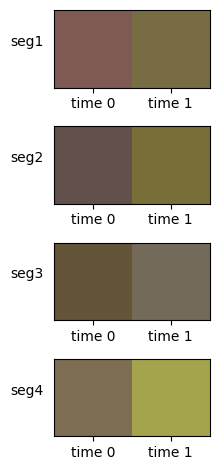

In [ ]:
import json, numpy as np, matplotlib.pyplot as plt
fig, axs = plt.subplots(len(SEGMENTOS), 1, figsize=(4, 1.2*len(SEGMENTOS)))
for i, ax in enumerate(np.atleast_1d(axs), 1):
    cores = json.load(open(f'{SAIDA}/seg{i}/meta.json'))['times_bgr']
    ax.imshow(np.array([[c[::-1] for c in cores.values()]], dtype=np.uint8))
    ax.set_xticks(range(len(cores))); ax.set_xticklabels([f'time {k}' for k in cores])
    ax.set_yticks([]); ax.set_ylabel(f'seg{i}', rotation=0, labelpad=20)
plt.tight_layout(); plt.show()

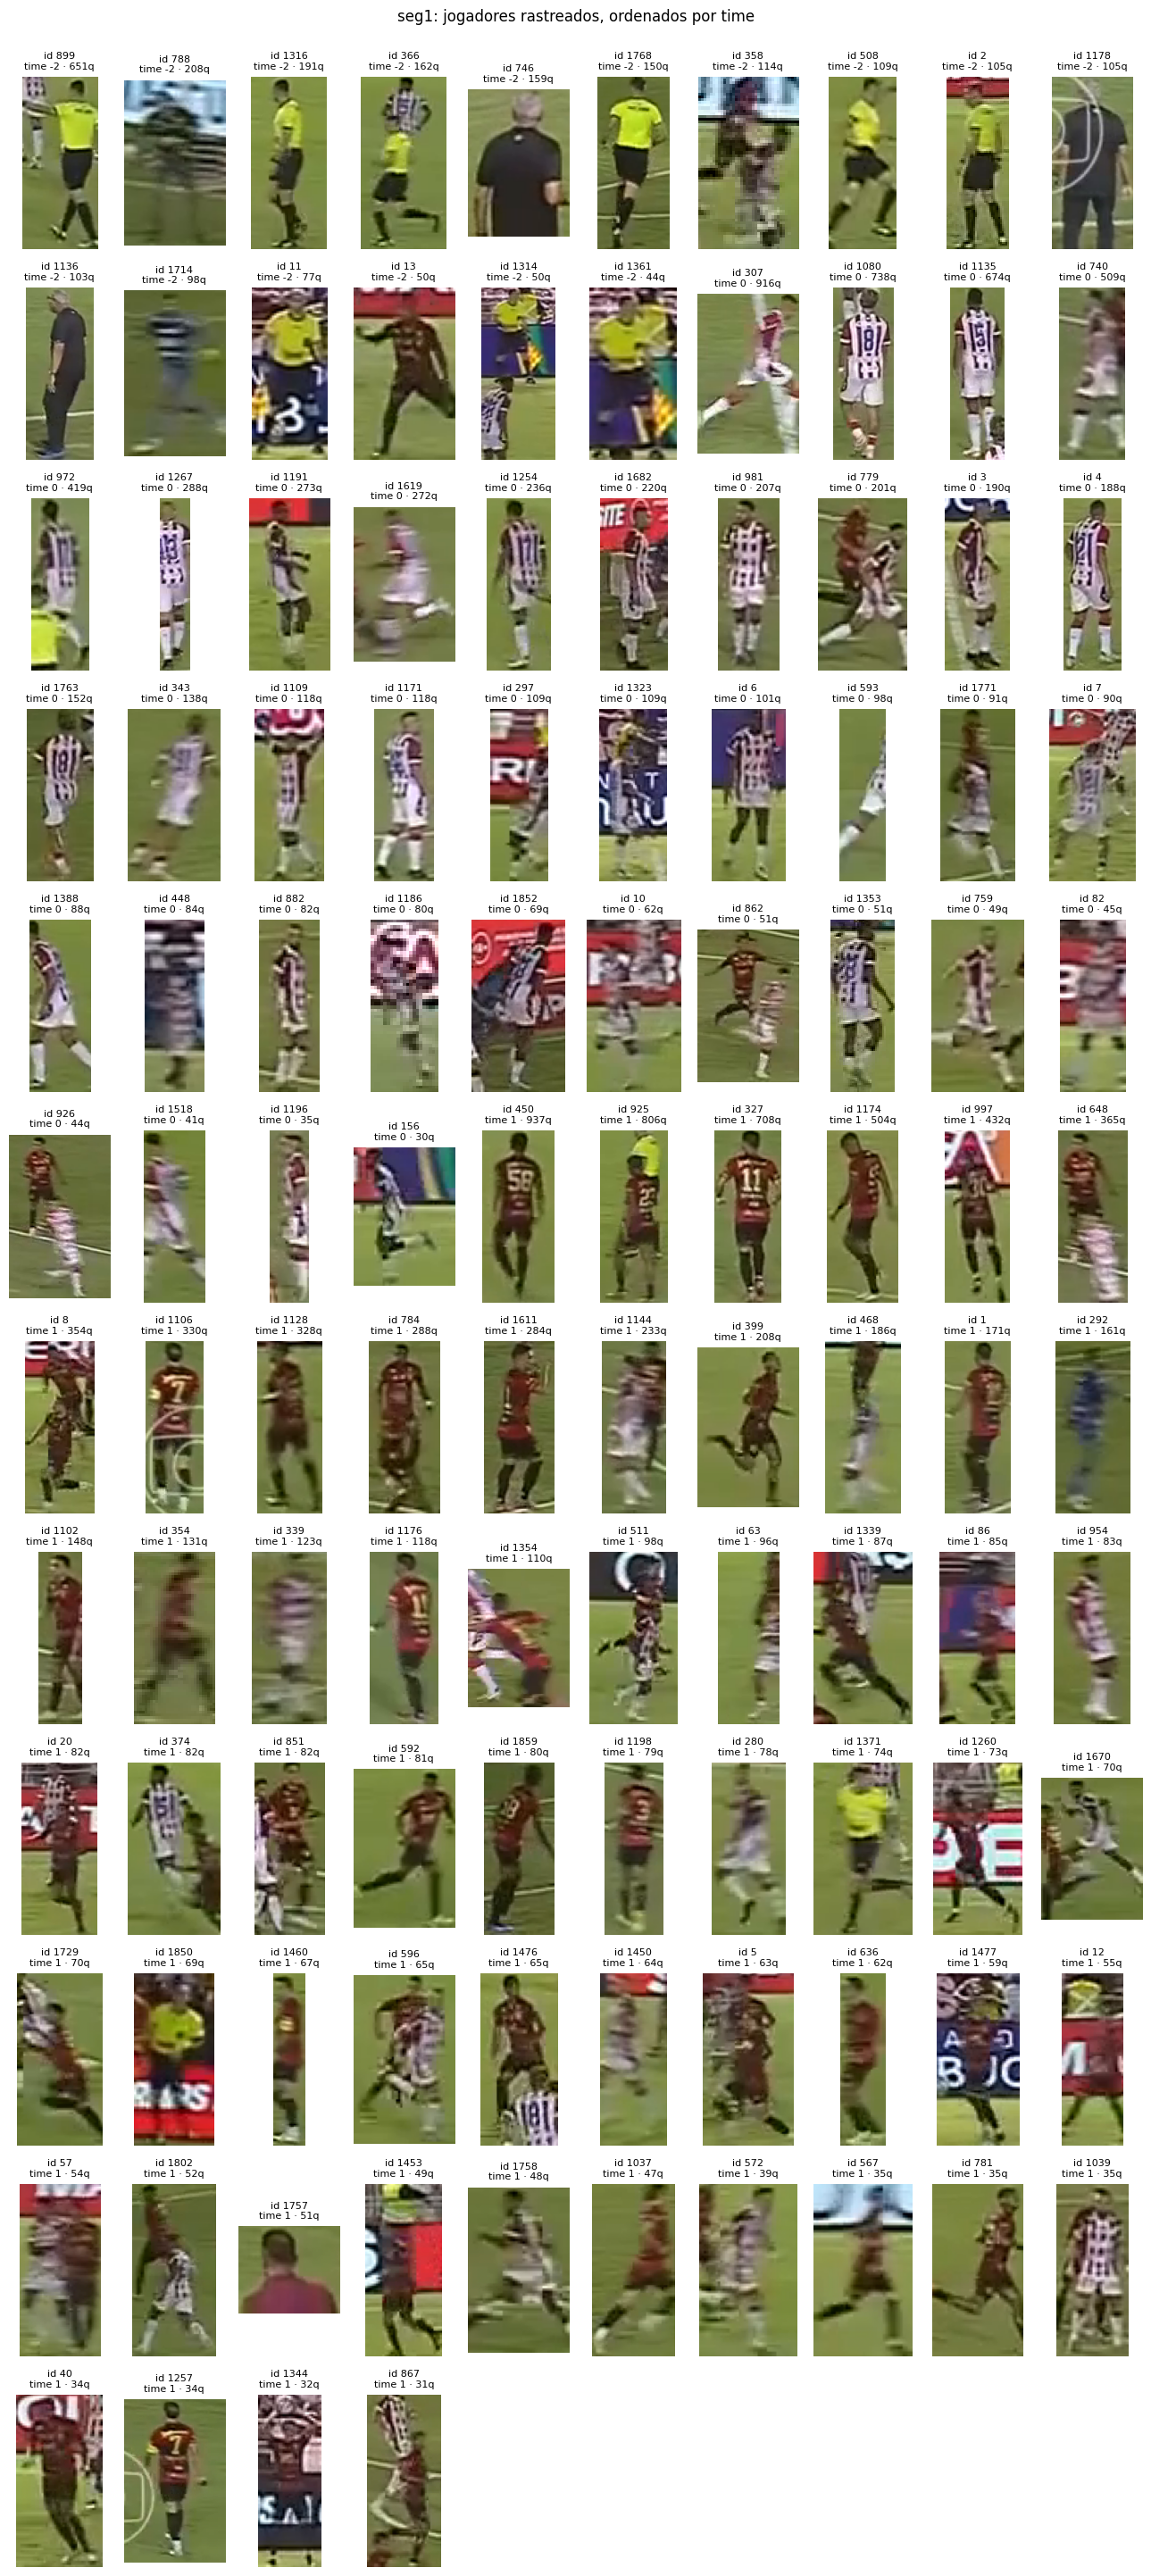

,n,time
track_id,,
899,651,-2.0
788,208,-2.0
1316,191,-2.0
366,162,-2.0
746,159,-2.0
...,...,...
1039,35,1.0
40,34,1.0
1257,34,1.0


In [ ]:
import cv2, json, numpy as np, pandas as pd, matplotlib.pyplot as plt

def galeria(seg, min_quadros=30, por_linha=10):
    pasta = f'{SAIDA}/{seg}'
    meta = json.load(open(f'{pasta}/meta.json'))
    tr = pd.read_csv(f'{pasta}/tracks.csv')
    tr = tr[(tr.classe != 'bola') & (tr.time != -1)]
    resumo = tr.groupby('track_id').agg(n=('frame', 'size'), time=('time', lambda s: s.value_counts().idxmax()))
    resumo = resumo[resumo.n >= min_quadros].sort_values(['time', 'n'], ascending=[True, False])
    cap = cv2.VideoCapture(meta['video']); ini = round(meta['inicio_s'] * meta['fps'])
    recortes = []
    for tid, r in resumo.iterrows():
        g = tr[tr.track_id == tid]
        d = g.loc[(g.y2 - g.y1).idxmax()]
        cap.set(cv2.CAP_PROP_POS_FRAMES, ini + int(d.frame)); ok, fr = cap.read()
        if not ok: continue
        x1, y1, x2, y2 = (int(d[c]) for c in ('x1', 'y1', 'x2', 'y2'))
        recortes.append((tid, int(r.time), int(r.n), cv2.cvtColor(fr[max(y1,0):y2, max(x1,0):x2], cv2.COLOR_BGR2RGB)))
    cap.release()
    linhas = int(np.ceil(len(recortes) / por_linha))
    fig, axs = plt.subplots(linhas, por_linha, figsize=(por_linha * 1.3, linhas * 2.4))
    for ax in np.ravel(axs): ax.axis('off')
    for ax, (tid, t, n, img) in zip(np.ravel(axs), recortes):
        ax.imshow(img); ax.set_title(f'id {tid}\ntime {t} · {n}q', fontsize=8)
    plt.suptitle(f'{seg}: jogadores rastreados, ordenados por time', y=1.0)
    plt.tight_layout(); plt.show()
    return resumo

galeria('seg1')

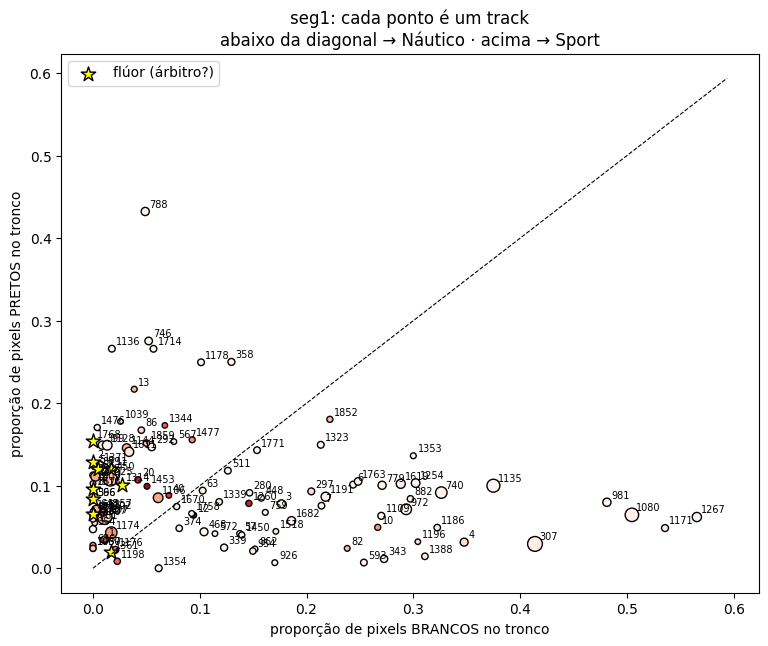

In [ ]:
import cv2, json, numpy as np, pandas as pd, matplotlib.pyplot as plt

LIM = dict(branco_V=150, branco_S=70, preto_V=60, arbitro_fluor=0.15)

def descritores(seg, passo=3):
    pasta = f'{SAIDA}/{seg}'
    meta = json.load(open(f'{pasta}/meta.json'))
    tr = pd.read_csv(f'{pasta}/tracks.csv')
    por_frame = {f: g for f, g in tr[tr.classe != 'bola'].groupby('frame')}
    cap = cv2.VideoCapture(meta['video'])
    cap.set(cv2.CAP_PROP_POS_FRAMES, round(meta['inicio_s'] * meta['fps']))
    linhas = []
    for f in range(meta['n_frames']):
        ok, fr = cap.read()
        if not ok: break
        if f % passo or f not in por_frame: continue
        hsv = cv2.cvtColor(fr, cv2.COLOR_BGR2HSV)
        for r in por_frame[f].itertuples():
            h, w = r.y2 - r.y1, r.x2 - r.x1
            if h < 30: continue
            c = hsv[int(r.y1 + .18*h):int(r.y1 + .50*h), int(r.x1 + .2*w):int(r.x2 - .2*w)].reshape(-1, 3).astype(int)
            if len(c) < 50: continue
            H, S, V = c[:, 0], c[:, 1], c[:, 2]
            linhas.append((r.track_id,
                           ((V > LIM['branco_V']) & (S < LIM['branco_S'])).mean(),
                           (V < LIM['preto_V']).mean(),
                           (((H < 10) | (H > 165)) & (S > 90) & (V > 60)).mean(),
                           ((H >= 20) & (H <= 40) & (S > 140) & (V > 170)).mean()))
    cap.release()
    d = pd.DataFrame(linhas, columns=['track_id', 'branco', 'preto', 'vermelho', 'fluor'])
    d = d.groupby('track_id').agg(n=('branco', 'size'), branco=('branco', 'median'), preto=('preto', 'median'),
                                  vermelho=('vermelho', 'median'), fluor=('fluor', 'median'))
    d.to_csv(f'{pasta}/times_descritores.csv')
    return d

def grafico(d, seg, min_n=10):
    d = d[d.n >= min_n]
    fig, ax = plt.subplots(figsize=(9, 7))
    ref = d.fluor > LIM['arbitro_fluor']
    ax.scatter(d.branco[~ref], d.preto[~ref], s=12 + d.n[~ref] / 3, c=d.vermelho[~ref], cmap='Reds', edgecolor='k')
    ax.scatter(d.branco[ref], d.preto[ref], s=120, marker='*', color='yellow', edgecolor='k', label='flúor (árbitro?)')
    for tid, r in d.iterrows():
        ax.annotate(str(tid), (r.branco, r.preto), fontsize=7, xytext=(3, 3), textcoords='offset points')
    lim = max(d.branco.max(), d.preto.max()) * 1.05
    ax.plot([0, lim], [0, lim], 'k--', lw=.8)
    ax.set_xlabel('proporção de pixels BRANCOS no tronco'); ax.set_ylabel('proporção de pixels PRETOS no tronco')
    ax.set_title(f'{seg}: cada ponto é um track\nabaixo da diagonal → Náutico · acima → Sport')
    ax.legend(); plt.show()

d1 = descritores('seg1'); grafico(d1, 'seg1')

In [ ]:
import os, shutil
REGRA = dict(fluor=0.15, preto_outros=0.20, branco_nautico=0.15)

def classificar(d):
    t = pd.Series(1, index=d.index)                    # Sport
    t[d.branco >= REGRA['branco_nautico']] = 0         # Náutico
    t[d.preto > REGRA['preto_outros']] = -2            # roupa escura: comissão técnica / torcida
    t[d.fluor > REGRA['fluor']] = -2                   # árbitro
    return t

for i in range(1, len(SEGMENTOS) + 1):
    seg = f'seg{i}'; p = f'{SAIDA}/{seg}'
    if not os.path.exists(f'{p}/tracks_original.csv'):
        shutil.copy(f'{p}/tracks.csv', f'{p}/tracks_original.csv')
    d = d1 if seg == 'seg1' else descritores(seg)
    t = classificar(d)
    tr = pd.read_csv(f'{p}/tracks_original.csv')
    pes = tr.classe != 'bola'
    tr.loc[pes, 'time'] = tr.loc[pes, 'track_id'].map(t).fillna(-1)
    tr.to_csv(f'{p}/tracks.csv', index=False)
    d.assign(time_novo=t).to_csv(f'{p}/times_descritores.csv')
    json.dump({'regra': REGRA, 'limiares_pixels': LIM,
               'convencao': {'0': 'Nautico', '1': 'Sport', '-2': 'arbitro/outros', '-1': 'sem dados'}},
              open(f'{p}/times_regra.json', 'w'), indent=2)
    print(seg, {'Náutico': int((t == 0).sum()), 'Sport': int((t == 1).sum()), 'outros': int((t == -2).sum())})

seg1 {'Náutico': 71, 'Sport': 111, 'outros': 35}
seg2 {'Náutico': 35, 'Sport': 64, 'outros': 54}
seg3 {'Náutico': 45, 'Sport': 79, 'outros': 35}
seg4 {'Náutico': 40, 'Sport': 32, 'outros': 11}


In [ ]:
for i in range(1, len(SEGMENTOS)+1):
    print(f'=== seg{i} ===')
    !python bola_kalman.py --saida {SAIDA}/seg{i}

=== seg1 ===
Bola detectada pelo YOLO :  1121 / 1859 quadros (60.3%), 1512 candidatas
Aceitas após gating      :   780
Preenchidas pelo Kalman  :   886
Cobertura final          : 89.6%  →  /content/drive/MyDrive/P3_VC/saidas/seg1/bola.csv
=== seg2 ===
Bola detectada pelo YOLO :   625 / 1202 quadros (52.0%), 716 candidatas
Aceitas após gating      :   453
Preenchidas pelo Kalman  :   606
Cobertura final          : 88.1%  →  /content/drive/MyDrive/P3_VC/saidas/seg2/bola.csv
=== seg3 ===
Bola detectada pelo YOLO :   648 / 915 quadros (70.8%), 930 candidatas
Aceitas após gating      :   490
Preenchidas pelo Kalman  :   396
Cobertura final          : 96.8%  →  /content/drive/MyDrive/P3_VC/saidas/seg3/bola.csv
=== seg4 ===
Bola detectada pelo YOLO :   406 / 654 quadros (62.1%), 444 candidatas
Aceitas após gating      :   368
Preenchidas pelo Kalman  :   252
Cobertura final          : 94.8%  →  /content/drive/MyDrive/P3_VC/saidas/seg4/bola.csv


In [4]:
   SEGMENTOS = [(0.0, 62.0), (68.9, 109.0), (152.0, 182.5), (186.2, 208.0)]

<IPython.core.display.Javascript object>

H0 salva em /content/drive/MyDrive/P3_VC/saidas/seg4/calibracao.json
  centro             erro = 0.31 m
  meio_sup           erro = 1.11 m
  meio_inf           erro = 0.17 m
  circulo_sup        erro = 0.33 m
  circulo_inf        erro = 0.11 m
  circulo_esq        erro = 1.12 m
  circulo_dir        erro = 0.64 m
  arco               erro médio = 0.27 m (máx 0.68 m, 30 pontos)
  sobre_linhas       erro médio = 0.10 m (máx 0.23 m, 20 pontos)


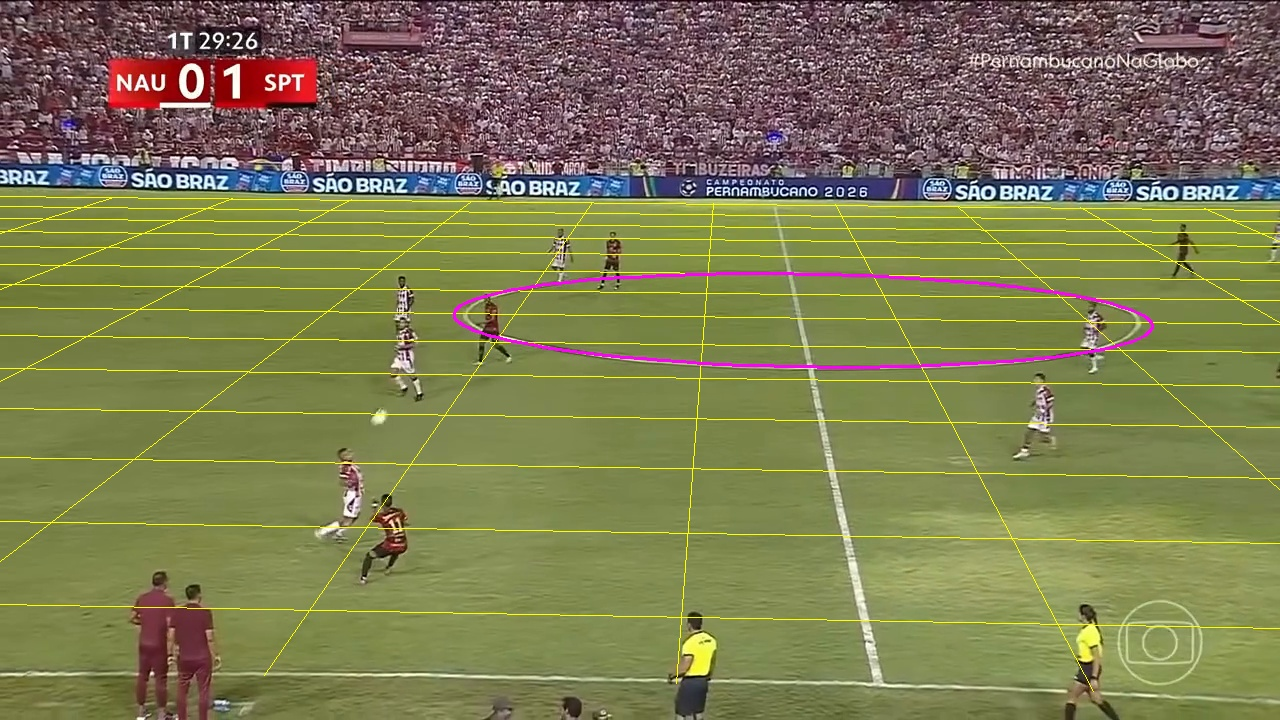

In [ ]:
   exec(open(f'{BASE}/calibracao_v2.py').read())
   calibrar_segmento('seg4')

**Próximo passo (Parte 4):** Kalman da bola e homografia — vamos montar juntos depois de ver o `rastreado.mp4`.

In [ ]:
import os
SEGMENTOS[1] = (68.9, 109.0)
SEGMENTOS[3] = (186.2, 208.0)
for i in (2, 4):
    a, b = SEGMENTOS[i - 1]; p = f'{SAIDA}/seg{i}'
    for f in ('tracks_original.csv', 'calibracao.json'):
        if os.path.exists(f'{p}/{f}'): os.remove(f'{p}/{f}')
    print(f'=== seg{i}: {a}s – {b}s ===')
    !python detectar_rastrear.py --video {VLOCAL30} --saida {p} --modelo yolov8m.pt --inicio {a/60} --fim {b/60} --imgsz 1280

=== seg2: 68.9s – 109.0s ===
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Device: cuda | Modelo: yolov8m.pt | 1280x720 @ 29.97 fps
Classes pessoa: ['person'] | bola: ['sports ball']
Rastreando:   0% 0/1201 [00:00<?, ?quadro/s]requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 191ms
Prepared 1 package in 55ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 0.5s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

Rastreando: 1202quadro [03:39,  5.47quadro/s]

1202 quadros em 219.9s (5.5 fps). Saída: /content/drive/MyDrive/P3_VC/saidas/seg2/
=== seg4: 186.2s – 208.0s ===
Device: cu

In [ ]:
SEGS_OK = ['seg1', 'seg2', 'seg4']
for s in SEGS_OK:
    print(f'=== {s} ===')
    !python homografia.py camera --saida {SAIDA}/{s}
    !python homografia.py projetar --saida {SAIDA}/{s}

=== seg1 ===
Traceback (most recent call last):
  File "/content/src/homografia.py", line 40, in <module>
    from campo import COMPRIMENTO, LARGURA, MARCOS
  File "/content/src/campo.py", line 11, in <module>
    import matplotlib.pyplot as plt
  File "/usr/local/lib/python3.13/dist-packages/matplotlib/pyplot.py", line 57, in <module>
    import matplotlib.colorbar
  File "/usr/local/lib/python3.13/dist-packages/matplotlib/colorbar.py", line 19, in <module>
    from matplotlib import _api, cbook, collections, cm, colors, contour, ticker
  File "/usr/local/lib/python3.13/dist-packages/matplotlib/contour.py", line 15, in <module>
    from matplotlib.backend_bases import MouseButton
  File "/usr/local/lib/python3.13/dist-packages/matplotlib/backend_bases.py", line 49, in <module>
    from matplotlib import (
        _api, backend_tools as tools, cbook, colors, _docstring, text,
        _tight_bbox, transforms, widgets, is_interactive, rcParams)
  File "/usr/local/lib/python3.13/dist-pack

In [ ]:
   !python homografia.py camera --saida {SAIDA}/seg1
   !python homografia.py projetar --saida {SAIDA}/seg1

Câmera: 100% 1859/1859 [03:18<00:00,  9.35it/s]
Homografias salvas em /content/drive/MyDrive/P3_VC/saidas/seg1/camera.npy (1859 quadros, 272 quadros-chave, 0 falhas)
Jogadores projetados: 98.0% válidos → tracks_campo.csv
Bola projetada: 95.7% válidos → bola_campo.csv


In [ ]:
ATAQUE_NAUTICO = 'esquerda'
for s in ['seg1', 'seg2', 'seg4']:
    print(f'=== {s} ===')
    !python metricas.py --saida {SAIDA}/{s} --raio-posse 2.0 --ataque-time0 {ATAQUE_NAUTICO}

=== seg1 ===
{
  "unidade": "m",
  "raio_posse": 2.0,
  "direcao_ataque": {
    "0": "esquerda",
    "1": "direita"
  },
  "quadros_com_bola": 1595,
  "quadros_total": 1859,
  "time0": {
    "posse_pct": 43.1,
    "passes": 2,
    "passes_certos": 1,
    "precisao_pct": 50.0,
    "distancia_total": 190.5
  },
  "time1": {
    "posse_pct": 56.9,
    "passes": 1,
    "passes_certos": 0,
    "precisao_pct": 0.0,
    "distancia_total": 297.5
  }
}

Top 5 distância (m):
 track_id  time  quadros   tempo_s  distancia  vel_media  vel_max  vel_max_kmh
      327     1      708 23.623600  31.040519   1.460416 6.188104    22.277175
      307     0      885 29.529500  26.776640   1.001869 6.081654    21.893955
        8     1      321 10.710700  25.246801   2.955654 9.406537    33.863535
      450     1      937 31.264567  21.693945   0.695367 3.616723    13.020201
        4     0      188  6.272933  15.467911   2.589798 5.312042    19.123351

3 passes → /content/drive/MyDrive/P3_VC/saidas/seg1/pas

In [8]:
   exec(open(f'{BASE}/anotar_passes.py').read())
   anotar('seg4')

<IPython.core.display.Javascript object>

(a anotação anterior foi guardada em passes_anotados_anterior.csv)
5 passes salvos em /content/drive/MyDrive/P3_VC/saidas/seg4/passes_anotados.csv
time     sucesso
Náutico  0          1
         1          4


In [9]:
import json, pandas as pd, sys
sys.path.insert(0, '/content/src'); from validar_passes import casar
linhas = []
for raio in (1.0, 2.0, 3.0):
    for s in ['seg1', 'seg2', 'seg4']:
        p = f'{SAIDA}/{s}'
        !python metricas.py --saida {p} --raio-posse {raio} --ataque-time0 esquerda > /dev/null
        m = json.load(open(f'{p}/metricas_times.json')); det = pd.read_csv(f'{p}/passes.csv')
        lin = dict(raio=raio, seg=s, posse_nautico=m['time0']['posse_pct'], passes_det=len(det))
        gt = pd.read_csv(f'{p}/passes_anotados.csv'); vp = len(casar(det, gt, 1.0))
        P = vp / len(det) if len(det) else 0; R = vp / len(gt) if len(gt) else 0
        lin.update(passes_anot=len(gt), VP=vp, precisao=round(P, 2), revocacao=round(R, 2),
                   F1=round(2 * P * R / (P + R), 2) if vp else 0)
        linhas.append(lin)
sens = pd.DataFrame(linhas); sens.to_csv(f'{SAIDA}/sensibilidade_raio.csv', index=False); sens

,raio,seg,posse_nautico,passes_det,passes_anot,VP,precisao,revocacao,F1
0,1.0,seg1,38.8,1,16,0,0.00,0.00,0.00
1,1.0,seg2,59.5,1,1,0,0.00,0.00,0.00
2,1.0,seg4,95.6,5,5,1,0.20,0.20,0.20
3,2.0,seg1,43.1,3,16,2,0.67,0.12,0.21
4,2.0,seg2,46.7,6,1,1,0.17,1.00,0.29
5,2.0,seg4,84.3,7,5,2,0.29,0.40,0.33
6,3.0,seg1,39.4,6,16,3,0.50,0.19,0.27
7,3.0,seg2,44.9,9,1,1,0.11,1.00,0.20
8,3.0,seg4,85.3,10,5,2,0.20,0.40,0.27


In [10]:
tot = sens.groupby('raio')[['passes_det', 'passes_anot', 'VP']].sum()
P = tot.VP / tot.passes_det; R = tot.VP / tot.passes_anot
tot['precisao'], tot['revocacao'], tot['F1'] = P.round(2), R.round(2), (2 * P * R / (P + R)).round(2)
tot.to_csv(f'{SAIDA}/sensibilidade_raio_total.csv'); print(tot, '\n')

RAIO = 2.0
for s in ['seg1', 'seg2', 'seg4']:
    print(f'=== {s} ===')
    !python metricas.py --saida {SAIDA}/{s} --raio-posse {RAIO} --ataque-time0 esquerda > /dev/null
    !python validar_passes.py --saida {SAIDA}/{s} --anotado {SAIDA}/{s}/passes_anotados.csv

      passes_det  passes_anot  VP  precisao  revocacao    F1
raio                                                        
1.0            7           22   1      0.14       0.05  0.07
2.0           16           22   5      0.31       0.23  0.26
3.0           25           22   6      0.24       0.27  0.26 

=== seg1 ===
Detectados: 3 | Anotados: 16 | Casados: 2
Precisão  : 0.67
Revocação : 0.12
F1        : 0.21
Acordo certo/errado nos casados: 0.50
=== seg2 ===
Detectados: 6 | Anotados: 1 | Casados: 1
Precisão  : 0.17
Revocação : 1.00
F1        : 0.29
Acordo certo/errado nos casados: 1.00
=== seg4 ===
Detectados: 7 | Anotados: 5 | Casados: 2
Precisão  : 0.29
Revocação : 0.40
F1        : 0.33
Acordo certo/errado nos casados: 0.50


In [11]:
!python xpass.py --saida {SAIDA}/seg2 > /dev/null
!python xpass.py --saida {SAIDA}/seg4 > /dev/null
!python xpass.py --saida {SAIDA}/seg1 --extra {SAIDA}/seg2/passes_features.csv {SAIDA}/seg4/passes_features.csv --what-if

16 passes (43.8% certos) — 3 deste trecho, 13 extras
Coeficientes (features padronizadas): {'distancia': np.float64(-0.374), 'adversarios_na_linha': np.float64(0.61), 'pressao_passador': np.float64(-0.075), 'espaco_destino': np.float64(0.421), 'progressao_x': np.float64(-0.858), 'dist_destino_gol': np.float64(0.31)}

                      AUC-ROC (↑)  Brier (↓)  Log-Loss (↓)  Avg Precision (↑)  média prevista  taxa observada
heuristico                  0.444      0.456         1.385              0.526           0.756           0.438
baseline (distância)        0.413      0.241         0.674              0.526           0.433           0.438
logistico                   0.524      0.295         0.845              0.553           0.398           0.438

Passes acima do esperado (PAx):
 passador  time  passes  certos  eXP   PAx
        6     0       1       1 1.00  0.00
     1663     1       1       0 0.65 -0.65
        3     0       1       0 0.73 -0.73
Superfície salva em /content/drive/M

In [12]:
import json, numpy as np, pandas as pd, sys
sys.path.insert(0, '/content/src'); from validar_passes import casar
linhas = []
for s in ['seg1', 'seg2', 'seg4']:
    p = f'{SAIDA}/{s}'; meta = json.load(open(f'{p}/meta.json')); m = json.load(open(f'{p}/metricas_times.json'))
    cal = json.load(open(f'{p}/calibracao.json'))['erros_m']; b = pd.read_csv(f'{p}/bola.csv')
    tc, bc = pd.read_csv(f'{p}/tracks_campo.csv'), pd.read_csv(f'{p}/bola_campo.csv')
    det, gt = pd.read_csv(f'{p}/passes.csv'), pd.read_csv(f'{p}/passes_anotados.csv')
    linhas.append(dict(segmento=s, inicio_no_clipe_s=meta['inicio_s'], duracao_s=round(meta['n_frames'] / meta['fps'], 1),
        bola_yolo_pct=round(100 * (b.fonte == 'detectada').sum() / meta['n_frames'], 1),
        bola_kalman_pct=round(100 * (b.fonte == 'kalman').sum() / meta['n_frames'], 1),
        jogadores_no_campo_pct=round(100 * tc.x_m.notna().mean(), 1), bola_no_campo_pct=round(100 * bc.x_m.notna().mean(), 1),
        calib_erro_max_marcos_m=round(max(cal['marcos']), 2), calib_erro_medio_arco_m=round(np.mean(cal['arco']), 2),
        posse_nautico_pct=m['time0']['posse_pct'], posse_sport_pct=m['time1']['posse_pct'], quadros_com_bola=m['quadros_com_bola'],
        passes_detectados=len(det), passes_anotados=len(gt), passes_casados=len(casar(det, gt, 1.0))))
r = pd.DataFrame(linhas); r.to_csv(f'{SAIDA}/resumo_segmentos.csv', index=False)
P, R = r.passes_casados.sum() / r.passes_detectados.sum(), r.passes_casados.sum() / r.passes_anotados.sum()
glob = dict(duracao_total_s=float(r.duracao_s.sum()), raio_posse_m=2.0,
            posse_nautico_ponderada_pct=round(float((r.posse_nautico_pct * r.quadros_com_bola).sum() / r.quadros_com_bola.sum()), 1),
            passes_detectados=int(r.passes_detectados.sum()), passes_anotados=int(r.passes_anotados.sum()),
            precisao=round(P, 2), revocacao=round(R, 2), F1=round(2 * P * R / (P + R), 2) if P + R else 0,
            segmento_descartado='seg3 (152-182.5 s): plano rasante na área, calibração inviável')
json.dump(glob, open(f'{SAIDA}/resumo_final.json', 'w'), indent=2, ensure_ascii=False)
display(r.T); print(json.dumps(glob, indent=2, ensure_ascii=False))

,0,1,2
segmento,seg1,seg2,seg4
inicio_no_clipe_s,0.0,68.9,186.2
duracao_s,62.0,40.1,21.8
bola_yolo_pct,42.0,37.7,56.3
bola_kalman_pct,47.7,50.4,38.5
jogadores_no_campo_pct,98.0,87.6,83.0
bola_no_campo_pct,95.7,86.7,76.9
calib_erro_max_marcos_m,0.58,0.96,1.12
calib_erro_medio_arco_m,0.07,0.16,0.27
posse_nautico_pct,43.1,46.7,84.3


{
  "duracao_total_s": 123.89999999999999,
  "raio_posse_m": 2.0,
  "posse_nautico_ponderada_pct": 50.8,
  "passes_detectados": 16,
  "passes_anotados": 22,
  "precisao": 0.31,
  "revocacao": 0.23,
  "F1": 0.26,
  "segmento_descartado": "seg3 (152-182.5 s): plano rasante na área, calibração inviável"
}


In [13]:
exec(open(f'{BASE}/video_apresentacao.py').read())
gerar_video(['seg1', 'seg4'], f'{BASE}/video_apresentacao.mp4')

seg1: 1859 quadros
seg4: 654 quadros
vídeo salvo em /content/drive/MyDrive/P3_VC/video_apresentacao.mp4


In [14]:
exec(open(f'{BASE}/montar_repo.py').read())
montar_repo()

⚠️ notebook não encontrado: baixe pelo menu Arquivo → Baixar .ipynb e coloque em notebook/
142 arquivos, 23.4 MB
vídeos no repositório: nenhum ✅
zip salvo em /content/drive/MyDrive/P3_VC/entrega_repo.zip
